In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("SaYoPillow.csv")
display(df.head(5))

,sr,rr,t,lm,bo,rem,sr.1,hr,sl
0,93.80,25.680,91.840,16.600,89.840,99.60,1.840,74.20,3
1,91.64,25.104,91.552,15.880,89.552,98.88,1.552,72.76,3
2,60.00,20.000,96.000,10.000,95.000,85.00,7.000,60.00,1
3,85.76,23.536,90.768,13.920,88.768,96.92,0.768,68.84,3
4,48.12,17.248,97.872,6.496,96.248,72.48,8.248,53.12,0


In [4]:
df = df.rename(columns={"sr":"Snoring Rate","rr": "Respiration rate","t":"Body Temperature","lm": "Limb Movement Rate","bo": "Blood Oxygen Levels","rem": "Eye movement","sr.1": "No. of hours of Sleep","hr": "Heart Rate","sl": "Stress Level"})

In [5]:
display(df.head(1))

,Snoring Rate,Respiration rate,Body Temperature,Limb Movement Rate,Blood Oxygen Levels,Eye movement,No. of hours of Sleep,Heart Rate,Stress Level
0,93.8,25.68,91.84,16.6,89.84,99.6,1.84,74.2,3


In [6]:
display(df.isna().sum())
print()
display(df.info())
print()
display(df.duplicated().sum())

Snoring Rate             0
Respiration rate         0
Body Temperature         0
Limb Movement Rate       0
Blood Oxygen Levels      0
Eye movement             0
No. of hours of Sleep    0
Heart Rate               0
Stress Level             0
dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 630 entries, 0 to 629
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Snoring Rate           630 non-null    float64
 1   Respiration rate       630 non-null    float64
 2   Body Temperature       630 non-null    float64
 3   Limb Movement Rate     630 non-null    float64
 4   Blood Oxygen Levels    630 non-null    float64
 5   Eye movement           630 non-null    float64
 6   No. of hours of Sleep  630 non-null    float64
 7   Heart Rate             630 non-null    float64
 8   Stress Level           630 non-null    int64  
dtypes: float64(8), int64(1)
memory usage: 44.4 KB


None

np.int64(0)

In [7]:
display(df["Stress Level"].value_counts())

Stress Level
3    126
1    126
0    126
2    126
4    126
Name: count, dtype: int64

In [8]:
display(df.describe())

,Snoring Rate,Respiration rate,Body Temperature,Limb Movement Rate,Blood Oxygen Levels,Eye movement,No. of hours of Sleep,Heart Rate,Stress Level
count,630.000000,630.000000,630.00000,630.000000,630.000000,630.000000,630.000000,630.000000,630.000000
mean,71.600000,21.800000,92.80000,11.700000,90.900000,88.500000,3.700000,64.500000,2.000000
std,19.372833,3.966111,3.52969,4.299629,3.902483,11.893747,3.054572,9.915277,1.415337
min,45.000000,16.000000,85.00000,4.000000,82.000000,60.000000,0.000000,50.000000,0.000000
25%,52.500000,18.500000,90.50000,8.500000,88.500000,81.250000,0.500000,56.250000,1.000000
50%,70.000000,21.000000,93.00000,11.000000,91.000000,90.000000,3.500000,62.500000,2.000000
75%,91.250000,25.000000,95.50000,15.750000,94.250000,98.750000,6.500000,72.500000,3.000000
max,100.000000,30.000000,99.00000,19.000000,97.000000,105.000000,9.000000,85.000000,4.000000


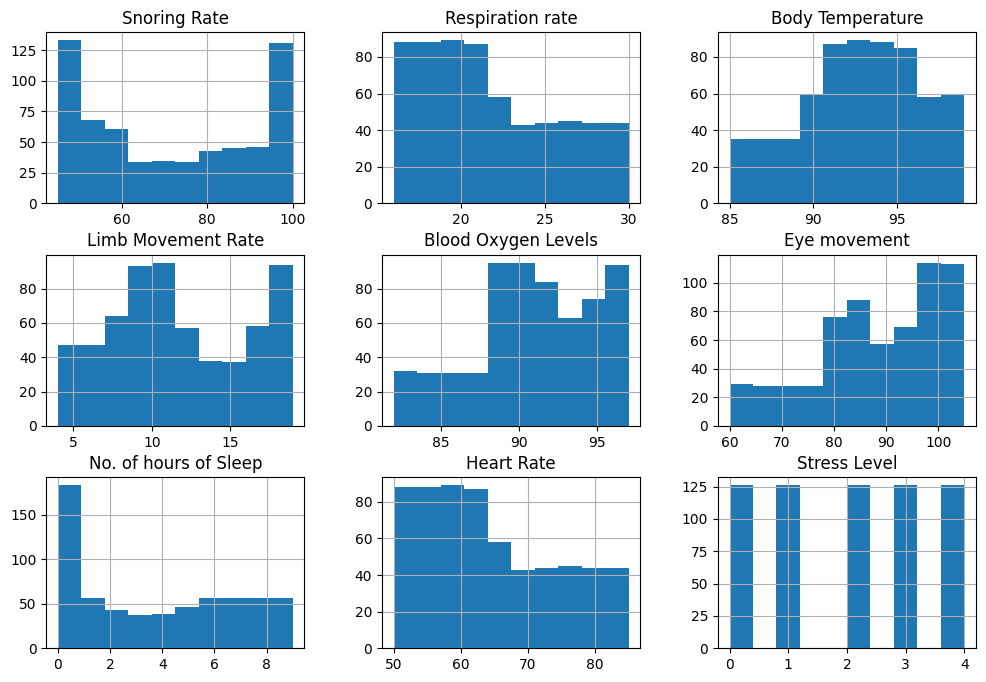

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

df.hist(figsize=(12,8))
plt.show()

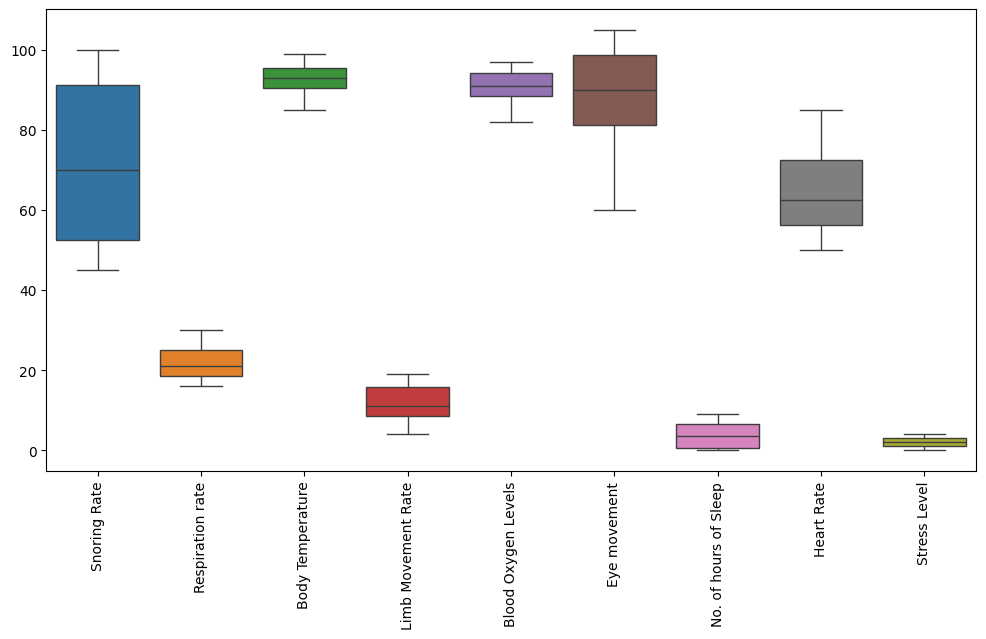

In [9]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df)
plt.xticks(rotation=90)
plt.show()

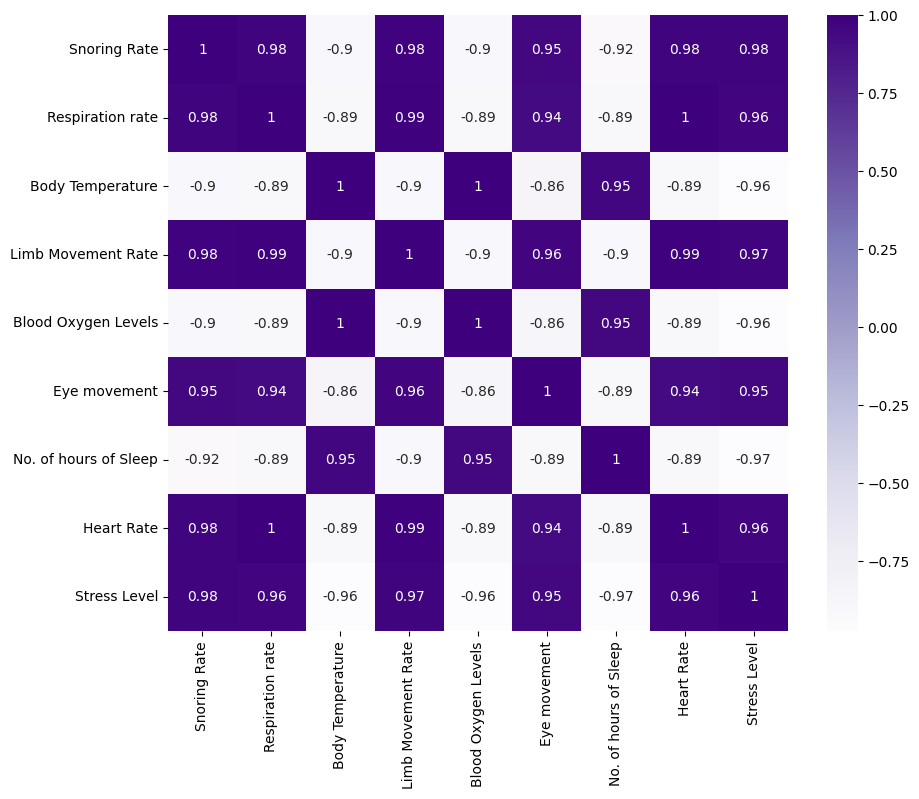

In [10]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap='Purples')
plt.show()

In [11]:
X = df.drop("Stress Level",axis = 1)
y = df["Stress Level"]

In [16]:
!pip install scikit-learn

  Using cached scikit_learn-1.8.0-cp311-cp311-macosx_12_0_arm64.whl.metadata (11 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 2.1 MB/s eta 0:00:00
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
Using cached scikit_learn-1.8.0-cp311-cp311-macosx_12_0_arm64.whl (8.1 MB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 1.7 MB/s eta 0:00:00m eta 0:00:010:00:01
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)

[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state = 42)

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Number of components:", pca.n_components_)

Number of components: 2


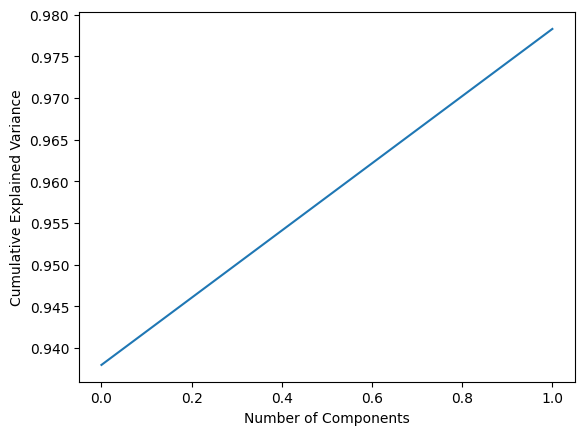

In [15]:
import numpy as np 

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

In [18]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_pca,y_train)
y_pred_log = log_model.predict(X_test_pca)
print("Logistic Regression Accuracy:",accuracy_score(y_test,y_pred_log))

train_acc = model.score(X_train_pca, y_train)
test_acc = model.score(X_test_pca, y_test)

print("Train Accuracy: ", train_acc)
print("Test Accuracy: ", test_acc)

Logistic Regression Accuracy: 1.0
Train Accuracy:  1.0
Test Accuracy:  1.0


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

model = RandomForestClassifier()
model.fit(X_train_pca, y_train)
y_pred = model.predict(X_test_pca)
print("Accuracy: ",accuracy_score(y_test,y_pred))

NameError: name 'X_train_pca' is not defined

In [41]:
train_acc = model.score(X_train_pca, y_train)
test_acc = model.score(X_test_pca, y_test)

print("Train Accuracy: ", train_acc)
print("Test Accuracy: ", test_acc)

NotFittedError: This RandomForestClassifier instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

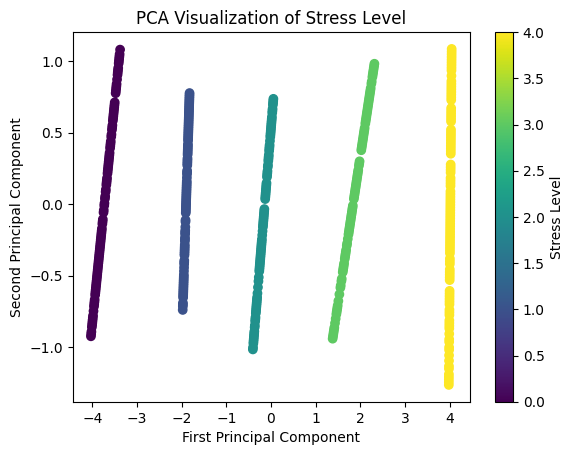

In [20]:
import matplotlib.pyplot as plt

plt.scatter(X_train_pca[:,0],X_train_pca[:,1],c=y_train,cmap="viridis")
plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("PCA Visualization of Stress Level")
plt.colorbar(label = "Stress Level")
plt.show()

In [9]:
from sklearn.datasets import make_classification
import pandas as pd

X, y = make_classification(
    n_samples=1500,
    n_features=8,
    n_informative=5,      # features actually affecting stress
    n_redundant=1,        # slightly correlated features
    n_classes=5,
    class_sep=2,        # controls difficulty
    random_state=42
)

columns = [
    "Snoring Rate",
    "Respiration Rate",
    "Body Temperature",
    "Limb Movement Rate",
    "Blood Oxygen Levels",
    "Eye Movement",
    "Sleep Hours",
    "Heart Rate"
]

df = pd.DataFrame(X, columns=columns)
df["Stress Level"] = y

In [10]:
df["Snoring Rate"] = df["Snoring Rate"]*10 + 70
df["Respiration Rate"] = df["Respiration Rate"]*3 + 20
df["Body Temperature"] = df["Body Temperature"]*1 + 37
df["Heart Rate"] = df["Heart Rate"]*10 + 70
df["Sleep Hours"] = df["Sleep Hours"]*2 + 6

In [11]:
X = df.drop("Stress Level", axis=1)
y = df["Stress Level"]

In [30]:
print("X:\n",X)
print()
print("y:\n",y)

X:
       Snoring Rate  Respiration Rate  Body Temperature  Limb Movement Rate  \
0        88.086057         22.367226         38.583265            0.953176   
1        72.949186         25.416251         34.101630            0.623526   
2        96.844732         19.933910         41.137363            0.790759   
3        59.938623         15.799786         35.990213            2.345624   
4        61.346943         18.692296         36.034631           -1.323650   
...            ...               ...               ...                 ...   
1495     66.925871         20.376646         34.288822            0.054052   
1496     53.905674         24.001995         35.224285            1.541321   
1497     60.248592         22.238072         40.088926            0.671270   
1498     69.153941         22.030982         41.677326            1.123427   
1499     72.902331         16.631256         35.266516           -0.753117   

      Blood Oxygen Levels  Eye Movement  Sleep Hours  Heart

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Number of components:", pca.n_components_)

Number of components: 7


In [15]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_pca, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [16]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=500,max_depth=10,random_state=42)

rf_model.fit(X_train_pca, y_train)

,n_estimators,500
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [17]:
y_pred = rf_model.predict(X_test_pca)

In [18]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        52
           1       0.95      0.95      0.95        61
           2       0.84      0.86      0.85        50
           3       0.91      0.88      0.89        72
           4       0.93      0.95      0.94        65

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



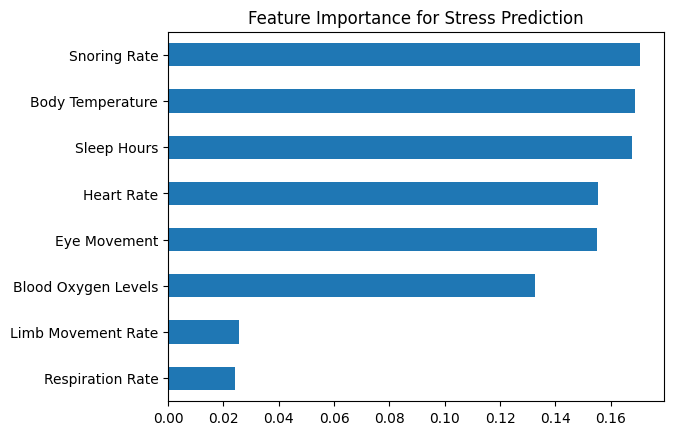

In [20]:
import matplotlib.pyplot as plt
rf_model_raw = RandomForestClassifier(n_estimators=500, random_state=42)

rf_model_raw.fit(X_train_scaled, y_train)

importance = rf_model_raw.feature_importances_

feat_importance = pd.Series(importance, index=X.columns)

feat_importance.sort_values().plot(kind="barh")

plt.title("Feature Importance for Stress Prediction")
plt.show()

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=500, random_state=42),
    "SVM": SVC(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc

In [22]:
for model, acc in results.items():
    print(model, ":", round(acc, 3))

Logistic Regression : 0.803
Random Forest : 0.903
SVM : 0.91
KNN : 0.91
Decision Tree : 0.773


In [23]:
import pandas as pd

df_results = pd.DataFrame(list(results.items()), columns=["Model", "Accuracy"])
print(df_results)

                 Model  Accuracy
0  Logistic Regression  0.803333
1        Random Forest  0.903333
2                  SVM  0.910000
3                  KNN  0.910000
4        Decision Tree  0.773333


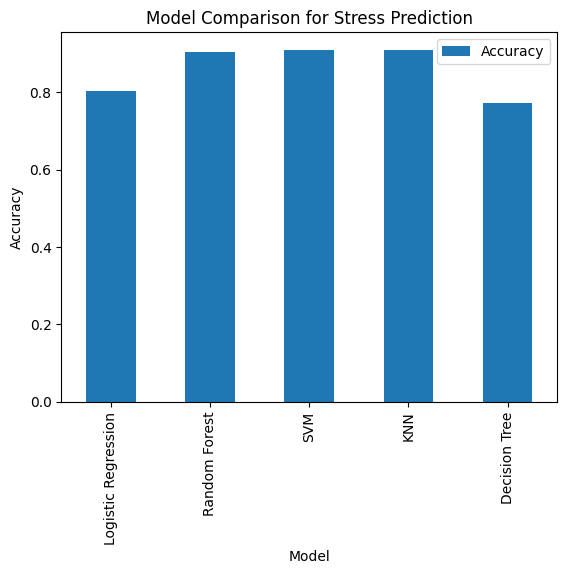

In [24]:
import matplotlib.pyplot as plt

df_results.set_index("Model").plot(kind="bar")

plt.ylabel("Accuracy")
plt.title("Model Comparison for Stress Prediction")
plt.show()

In [25]:
import joblib

joblib.dump(rf_model,"random_forest_model.pkl")
print("Model saved successfully")

Model saved successfully


In [28]:
rfm = joblib.load("random_forest_model.pkl")
y_pred = rfm.predict(X_test_pca)
acc = accuracy_score(y_test, y_pred)
print(acc)

0.9
